# TrustLab — Unsupervised Learning: Discovering Player Strategies

**Goal:** find groups of players who play the Trust Game (repeated Prisoner's Dilemma) in a similar way, and understand what makes players cooperate or change their decision.

**Questions from the project plan answered here**
1. Which behavioral strategies are most common?
2. How does cooperation differ between fixed-partner and changing-partner games?
3. Which factors are associated with players changing their decision?

**Dataset:** the same data as the supervised notebook: 188 players × 100 rounds.
- `fix.csv`: Fixed Partner (same opponent for all rounds)
- `rand.csv`: Random Partner (new opponent every round)

**Workflow (Unit 5):** Preprocessing → Feature Engineering → Scaling → K-Means → Other models (Hierarchical, GMM, DBSCAN) → Model Comparison → Dimensionality Reduction → Interpretation → Decision Analysis

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.cluster import AgglomerativeClustering
from sklearn.cluster import DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score

from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.stats import chi2_contingency

import os, warnings
os.environ["LOKY_MAX_CPU_COUNT"] = "4"   # avoids a harmless warning on Windows
warnings.filterwarnings("ignore")

In [2]:
DATA_PATH = "../data/"      # in Google Colab use "/content/"
FIG_PATH = "../figures/"

# one color per strategy (used in every plot)
strategy_colors = {"Forgiving Cooperator": "#2a78d6", "Reciprocator": "#eb6834",
                   "Erratic": "#1baf7a", "Defector": "#eda100"}
strategy_order = list(strategy_colors)

## 1. Data Loading

In [3]:
fix = pd.read_csv(DATA_PATH + "fix.csv", sep=";")
rand = pd.read_csv(DATA_PATH + "rand.csv", sep=";")
survey = pd.read_csv(DATA_PATH + "UserInformation.csv", sep=";")

print("Fixed Dataset:", fix.shape)
print("Random Dataset:", rand.shape)
print("Survey:", survey.shape)

Fixed Dataset: (9200, 15)
Random Dataset: (9600, 14)
Survey: (188, 7)


The full EDA (target distribution, cooperation across rounds, effect of previous decisions) is in the **supervised notebook**. Here we only prepare the data for clustering.

## 2. Data Preprocessing (same steps as the supervised notebook)

In [4]:
# merge datasets
columns = ["player", "session", "round", "treatment", "prev_player", "prev_opp",
           "action_player", "action_opponent", "payoff"]

df = pd.concat([fix[columns], rand[columns]], ignore_index=True)

# Handling missing values (ND: no decision, only in round 1)
df["prev_player"] = df["prev_player"].fillna("ND")
df["prev_opp"] = df["prev_opp"].fillna("ND")

# Target encoding: 1 = Cooperate, 0 = Defect
df["y"] = df["action_player"].map({"C": 1, "D": 0})

# Previous round as one state: <my previous move><opponent's previous move>
df["prev_state"] = df["prev_player"] + df["prev_opp"]

# Payoff of the previous round (sort so that each player's rounds are in order)
df = df.sort_values(["player", "round"]).reset_index(drop=True)
df["prev_payoff"] = df.groupby("player")["payoff"].shift(1)

print(df.shape)
df.head()

(18800, 12)


,player,session,round,treatment,prev_player,prev_opp,action_player,action_opponent,payoff,y,prev_state,prev_payoff
0,s10n5usuario1,s10n5,1,fix,ND,ND,D,C,4,0,NDND,NaN
1,s10n5usuario1,s10n5,2,fix,D,C,D,D,1,0,DC,4.0
2,s10n5usuario1,s10n5,3,fix,D,D,C,D,0,1,DD,1.0
3,s10n5usuario1,s10n5,4,fix,C,D,D,C,4,0,CD,0.0
4,s10n5usuario1,s10n5,5,fix,D,C,D,C,4,0,DC,4.0


| prev_state | Meaning |
|---|---|
| `CC` | both cooperated |
| `CD` | I cooperated, the opponent defected (**I was betrayed**) |
| `DC` | I defected, the opponent cooperated (**I exploited**) |
| `DD` | both defected |
| `NDND` | round 1, no previous round |

In [5]:
# Survey answers (used later to check the clusters)
survey.columns = ["user_id", "age", "gender", "influenced_by_opponent", "influenced_by_self",
                  "session", "treatment"]
survey["player"] = survey["session"] + survey["user_id"]
survey = survey.set_index("player")

print("Survey players found in the game data:", survey.index.isin(df["player"]).sum(), "/", len(survey))

Survey players found in the game data: 188 / 188


## 3. Feature Engineering

Clustering groups **players**, not single decisions, so we need **one row per player** that describes *how* the player plays (their strategy).

**Main features (used for clustering)**

| Feature | Meaning |
|---|---|
| `coop_rate` | % of rounds the player cooperated |
| `p_c_after_CC` | chance of cooperating after both cooperated |
| `p_c_after_CD` | chance of cooperating after **being betrayed** |
| `p_c_after_DC` | chance of cooperating after **exploiting** the opponent |
| `p_c_after_DD` | chance of cooperating after both defected |

These four "chance of cooperating after ..." values are the classic way to describe a strategy. For example, **Tit-for-Tat** = (1, 0, 1, 0): cooperate only if the opponent cooperated last round.

**Problem: rare situations.** Some players almost never reach a situation. For example, a player who always defects is almost never in `CC`. If they were in `CC` only once, their value would be exactly 0 or 1, which is not reliable.

**Solution: smoothing.** We add `alpha = 2` imaginary rounds that behave like the average player:

$$p = \frac{\text{cooperations after the state} + \alpha \cdot \text{average}}{\text{visits to the state} + \alpha}$$

Players with many visits keep their own value. Players with very few visits are pulled towards the average.

In [6]:
# Average chance of cooperating after each state (all players)
rounds_with_prev = df[df["prev_state"] != "NDND"]
state_avg = rounds_with_prev.groupby("prev_state")["y"].mean()
print(state_avg.round(3))

prev_state
CC    0.925
CD    0.584
DC    0.211
DD    0.119
Name: y, dtype: float64


In [7]:
def build_player_features(df, alpha=2):
    """One row per player with the strategy features."""
    rounds_with_prev = df[df["prev_state"] != "NDND"]
    state_avg = rounds_with_prev.groupby("prev_state")["y"].mean()

    # how many times each player was in each state, and how many of those times they cooperated next
    visits = rounds_with_prev.pivot_table(index="player", columns="prev_state", values="y",
                                          aggfunc="count", fill_value=0)
    coops = rounds_with_prev.pivot_table(index="player", columns="prev_state", values="y",
                                         aggfunc="sum", fill_value=0)

    players = pd.DataFrame(index=visits.index)
    players["treatment"] = df.groupby("player")["treatment"].first()
    players["coop_rate"] = df.groupby("player")["y"].mean()
    for state in ["CC", "CD", "DC", "DD"]:
        players["p_c_after_" + state] = (coops[state] + alpha * state_avg[state]) / (visits[state] + alpha)
        players["visits_" + state] = visits[state]
    return players

In [8]:
player_df = build_player_features(df, alpha=2)

# Extra features: NOT used for clustering, only to describe the clusters later
df["switched"] = (df["prev_player"] != "ND") & (df["prev_player"] != df["action_player"])
player_df["switch_rate"] = df[df["round"] > 1].groupby("player")["switched"].mean()
player_df["mean_payoff"] = df.groupby("player")["payoff"].mean()
player_df["influenced_by_opponent"] = survey["influenced_by_opponent"] == "Yes"

print(player_df.shape)
player_df.head()

(188, 13)


,treatment,coop_rate,p_c_after_CC,visits_CC,p_c_after_CD,visits_CD,p_c_after_DC,visits_DC,p_c_after_DD,visits_DD,switch_rate,mean_payoff,influenced_by_opponent
player,,,,,,,,,,,,,
s10n5usuario1,fix,0.12,0.569886,3,0.197169,9,0.193648,26,0.083149,61,0.202020,1.75,True
s10n5usuario2,fix,0.36,0.587016,25,0.397604,11,0.231603,43,0.329016,20,0.353535,2.71,True
s10n5usuario3,fix,0.97,0.998432,94,0.292215,2,0.605536,2,0.079453,1,0.040404,2.94,True
s10n5usuario4,fix,0.97,0.988015,94,0.792215,2,0.355536,2,0.412787,1,0.030303,2.94,True
s10n5usuario5,fix,0.30,0.958908,26,0.433772,3,0.158016,7,0.034436,63,0.060606,1.72,True


In [9]:
features = ["coop_rate", "p_c_after_CC", "p_c_after_CD", "p_c_after_DC", "p_c_after_DD"]

player_df[features].describe().round(3)

,coop_rate,p_c_after_CC,p_c_after_CD,p_c_after_DC,p_c_after_DD
count,188.000,188.000,188.000,188.000,188.000
mean,0.420,0.838,0.481,0.264,0.170
std,0.329,0.201,0.212,0.224,0.166
min,0.000,0.231,0.078,0.011,0.002
25%,0.120,0.713,0.310,0.082,0.051
50%,0.335,0.925,0.495,0.211,0.118
75%,0.690,0.988,0.585,0.430,0.235
max,1.000,0.999,0.991,0.901,0.816


In [10]:
print("Players who visited a state fewer than 3 times:")
for state in ["CC", "CD", "DC", "DD"]:
    print(" ", state, ":", (player_df["visits_" + state] < 3).sum())

Players who visited a state fewer than 3 times:
  CC : 45
  CD : 43
  DC : 29
  DD : 19


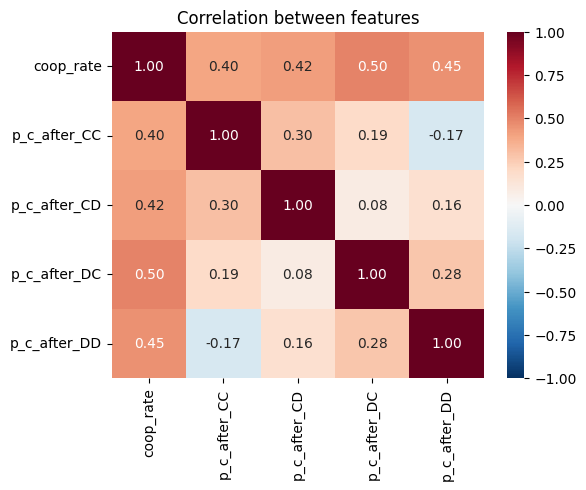

In [11]:
plt.figure(figsize=(6, 4.5))
sns.heatmap(player_df[features].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1)
plt.title("Correlation between features")
plt.show()

The features are only moderately correlated (max ≈ 0.5), so each one adds different information and we keep all five.

## 4. Feature Scaling

In [12]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(player_df[features])

print(X_scaled.shape)

(188, 5)


K-Means, Hierarchical clustering and GMM all use **distances**, so every feature is standardised (mean 0, std 1). Otherwise a feature with a bigger spread would dominate the clusters.

## 5. K-Means Clustering

### 5.1 Choosing the number of clusters (k)

In [13]:
k_values = range(2, 9)
inertia = []
silhouette = []
stability = []

for k in k_values:
    model = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = model.fit_predict(X_scaled)
    inertia.append(model.inertia_)
    silhouette.append(silhouette_score(X_scaled, labels))

    # stability: do other random starts give the same clusters? (1 = identical)
    other_runs = [KMeans(n_clusters=k, n_init=10, random_state=s).fit_predict(X_scaled) for s in range(10)]
    stability.append(np.mean([adjusted_rand_score(labels, other) for other in other_runs]))

k_results = pd.DataFrame({"k": k_values, "inertia": inertia, "silhouette": silhouette, "stability": stability})
k_results.round(3)

,k,inertia,silhouette,stability
0,2,628.653,0.318,0.985
1,3,507.417,0.306,0.985
2,4,413.383,0.316,1.000
3,5,343.818,0.315,0.986
4,6,309.336,0.319,0.884
5,7,285.603,0.310,0.606
6,8,255.769,0.276,0.760


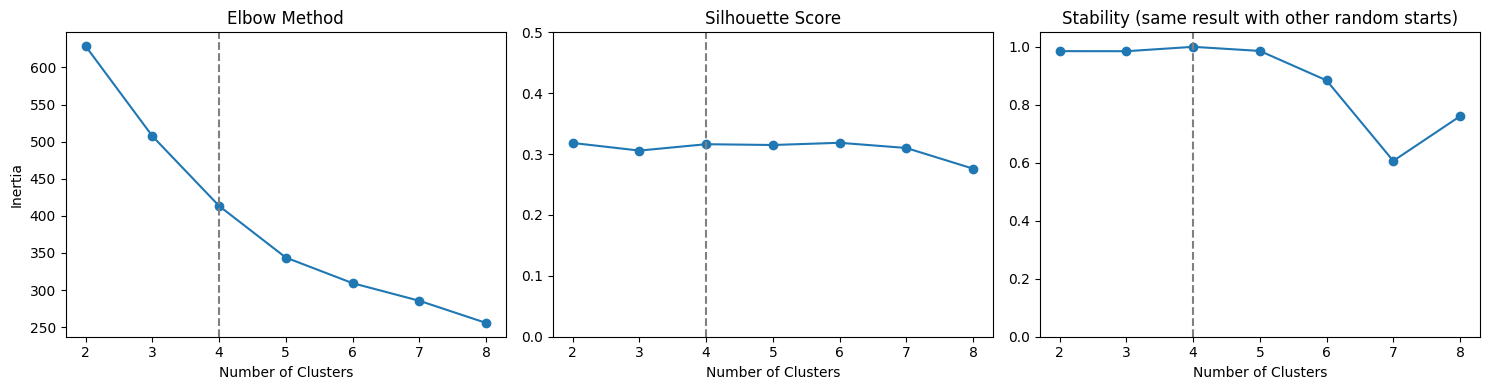

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(k_values, inertia, marker="o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of Clusters")
axes[0].set_ylabel("Inertia")

axes[1].plot(k_values, silhouette, marker="o")
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of Clusters")
axes[1].set_ylim(0, 0.5)

axes[2].plot(k_values, stability, marker="o")
axes[2].set_title("Stability (same result with other random starts)")
axes[2].set_xlabel("Number of Clusters")
axes[2].set_ylim(0, 1.05)

for ax in axes:
    ax.axvline(4, color="gray", linestyle="--")
plt.tight_layout()
plt.savefig(FIG_PATH + "u01_choose_k.png", dpi=150, bbox_inches="tight")
plt.show()

**We choose k = 4.**
- **Silhouette** is almost the same for k = 2 to 6 (≈ 0.31–0.32), so it cannot decide alone. Players' strategies change gradually instead of forming clearly separated groups.
- **Elbow:** there is no sharp elbow. Inertia drops by about 70–120 per extra cluster up to k = 5, and by 35 or less after that.
- **Stability:** with k = 4, every random start gives exactly the same clusters (1.00). From k = 6, the result depends on the random start.
- **Interpretation:** k = 2 only splits "cooperative" from "uncooperative" players. k = 4 gives four different behaviors, which answers *"which strategies exist?"*.

### 5.2 Apply K-Means

In [15]:
kmeans = KMeans(n_clusters=4, n_init=10, random_state=42)
player_df["cluster"] = kmeans.fit_predict(X_scaled)

print(player_df["cluster"].value_counts().sort_index())
print("Silhouette Score:", round(silhouette_score(X_scaled, player_df["cluster"]), 3))

cluster
0    55
1    31
2    29
3    73
Name: count, dtype: int64
Silhouette Score: 0.316


In [16]:
profile = player_df.groupby("cluster")[features + ["switch_rate", "mean_payoff"]].mean()
profile["players"] = player_df["cluster"].value_counts()
profile.round(2)

,coop_rate,p_c_after_CC,p_c_after_CD,p_c_after_DC,p_c_after_DD,switch_rate,mean_payoff,players
cluster,,,,,,,,
0,0.80,0.95,0.69,0.34,0.26,0.13,2.05,55
1,0.28,0.49,0.32,0.22,0.29,0.34,1.76,31
2,0.58,0.95,0.33,0.58,0.13,0.23,2.07,29
3,0.13,0.86,0.45,0.10,0.06,0.10,1.62,73


### 5.3 Naming the clusters

We name each cluster from its profile:
- **lowest** cooperation rate → **Defector**
- **highest** cooperation rate → **Forgiving Cooperator**
- of the two middle clusters, the one that keeps cooperating after mutual cooperation (higher `p_c_after_CC`) → **Reciprocator**, the other → **Erratic**

We write this rule as a function so we can reuse it for the other models later.

In [17]:
def name_clusters(player_df, labels):
    """Give each cluster a strategy name, based on its average profile."""
    profile = player_df.groupby(labels)[features].mean()
    order = profile.sort_values("coop_rate").index

    names = {order[0]: "Defector", order[-1]: "Forgiving Cooperator"}
    middle = profile.loc[order[1:3]].sort_values("p_c_after_CC")
    names[middle.index[0]] = "Erratic"
    names[middle.index[1]] = "Reciprocator"
    return pd.Series(labels, index=player_df.index).map(names)

In [18]:
player_df["strategy"] = name_clusters(player_df, player_df["cluster"].values)

strategy_profile = player_df.groupby("strategy")[features + ["switch_rate", "mean_payoff"]].mean().loc[strategy_order]
strategy_profile["players"] = player_df["strategy"].value_counts()
strategy_profile.round(2)

,coop_rate,p_c_after_CC,p_c_after_CD,p_c_after_DC,p_c_after_DD,switch_rate,mean_payoff,players
strategy,,,,,,,,
Forgiving Cooperator,0.80,0.95,0.69,0.34,0.26,0.13,2.05,55
Reciprocator,0.58,0.95,0.33,0.58,0.13,0.23,2.07,29
Erratic,0.28,0.49,0.32,0.22,0.29,0.34,1.76,31
Defector,0.13,0.86,0.45,0.10,0.06,0.10,1.62,73


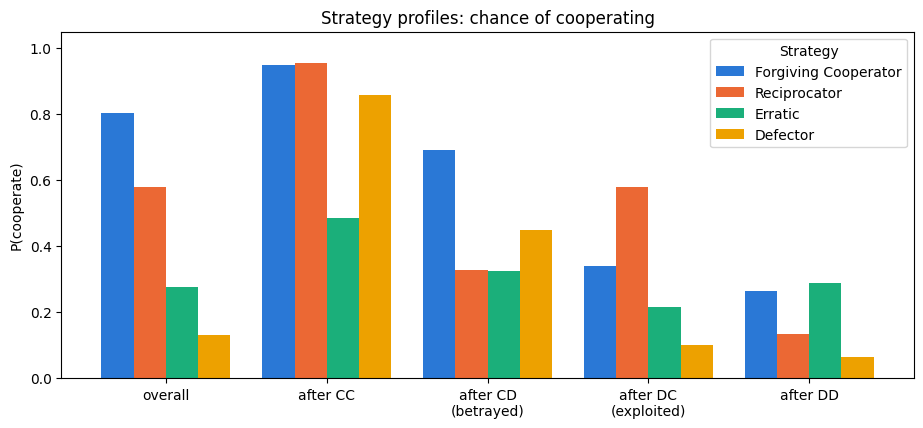

In [19]:
strategy_profile[features].T.plot(kind="bar", figsize=(11, 4.5), width=0.8,
                                  color=[strategy_colors[s] for s in strategy_order])
plt.title("Strategy profiles: chance of cooperating")
plt.ylabel("P(cooperate)")
plt.xticks(range(5), ["overall", "after CC", "after CD\n(betrayed)", "after DC\n(exploited)", "after DD"], rotation=0)
plt.ylim(0, 1.05)
plt.legend(title="Strategy")
plt.savefig(FIG_PATH + "u02_strategy_profiles.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretation**

| Strategy | Players | How they play |
|---|---|---|
| **Forgiving Cooperator** | 55 | cooperates in 80% of rounds and keeps cooperating even after being betrayed (69%) |
| **Reciprocator** | 29 | cooperates after the opponent cooperated (CC, DC) and defects after the opponent defected (CD, DD): copies the opponent |
| **Erratic** | 31 | breaks mutual cooperation half of the time (0.49) and changes decision most often (34% of rounds) |
| **Defector** | 73 | cooperates in only 13% of rounds and almost never leaves mutual defection (0.06) |

*Note:* the Defectors' high value after CC (0.86) comes mostly from the smoothing. These players were in CC only about 2 times in 100 rounds, so their value is pulled towards the average (0.925). Section 9 shows their real behavior.

## 6. Other Clustering Models

We compare K-Means with two other models:
- **Hierarchical Clustering** builds clusters by merging the closest players step by step (dendrogram).
- **Gaussian Mixture Model (GMM)** treats each strategy as a "cloud" and gives every player a *probability* of belonging to each cluster.

We also try **DBSCAN** (density-based), as in the course.

### 6.1 Hierarchical Clustering

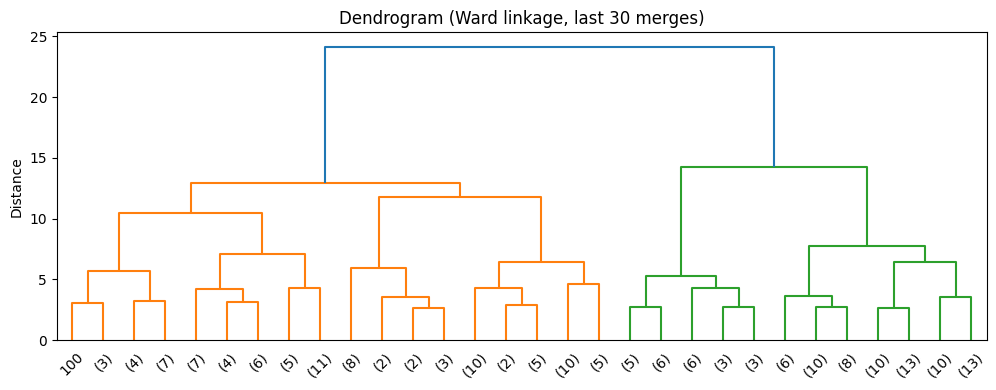

In [20]:
Z = linkage(X_scaled, method="ward")

plt.figure(figsize=(12, 4))
dendrogram(Z, truncate_mode="lastp", p=30)
plt.title("Dendrogram (Ward linkage, last 30 merges)")
plt.ylabel("Distance")
plt.show()

In [21]:
# Hyperparameter tuning: which linkage works best with 4 clusters?
for method in ["ward", "average", "complete", "single"]:
    hc = AgglomerativeClustering(n_clusters=4, linkage=method)
    labels = hc.fit_predict(X_scaled)
    print(f"{method:9s} silhouette = {silhouette_score(X_scaled, labels):.3f}   "
          f"smallest cluster = {np.bincount(labels).min()} players")

ward      silhouette = 0.259   smallest cluster = 23 players
average   silhouette = 0.276   smallest cluster = 1 players
complete  silhouette = 0.193   smallest cluster = 15 players
single    silhouette = 0.008   smallest cluster = 1 players


`average` and `single` linkage put **only 1 player** in a cluster (they separate outliers instead of strategies), and `complete` has a low silhouette. **Ward** linkage gives four real groups, so we use it.

In [22]:
hc = AgglomerativeClustering(n_clusters=4, linkage="ward")
labels_hc = hc.fit_predict(X_scaled)
player_df["strategy_hc"] = name_clusters(player_df, labels_hc)

print(player_df["strategy_hc"].value_counts())
print("Silhouette Score:", round(silhouette_score(X_scaled, labels_hc), 3))

strategy_hc
Defector                70
Reciprocator            48
Forgiving Cooperator    47
Erratic                 23
Name: count, dtype: int64
Silhouette Score: 0.259


### 6.2 Gaussian Mixture Model (GMM)

In [23]:
# Hyperparameter tuning with BIC (lower = better)
bic = pd.DataFrame(index=range(1, 9))
for cov in ["full", "tied", "diag", "spherical"]:
    bic[cov] = [GaussianMixture(n_components=k, covariance_type=cov, n_init=5, random_state=42).fit(X_scaled).bic(X_scaled)
                for k in range(1, 9)]
bic.index.name = "k"
bic.round(0)

,full,tied,diag,spherical
k,,,,
1,2557.0,2557.0,2720.0,2699.0
2,2257.0,2508.0,2437.0,2533.0
3,1981.0,2446.0,2182.0,2443.0
4,1953.0,2357.0,2070.0,2423.0
5,2017.0,2340.0,2040.0,1945.0
6,2062.0,2281.0,1910.0,1898.0
7,2047.0,2271.0,1774.0,1883.0
8,2132.0,2279.0,1827.0,1872.0


In [24]:
print("Best covariance type for k = 4:", bic.loc[4].idxmin())
print("Lowest BIC overall: k =", bic.stack().idxmin()[0], "with", bic.stack().idxmin()[1])

Best covariance type for k = 4: full
Lowest BIC overall: k = 7 with diag


With 4 clusters, BIC prefers **full** covariance. Over all k, BIC keeps asking for more and more clusters. This is a sign that the data are not really Gaussian (our features are probabilities between 0 and 1, many close to 0 or 1). We keep k = 4 so that all models are compared on the same number of clusters.

In [25]:
gmm = GaussianMixture(n_components=4, covariance_type="full", n_init=5, random_state=42)
labels_gmm = gmm.fit_predict(X_scaled)
player_df["strategy_gmm"] = name_clusters(player_df, labels_gmm)

print(player_df["strategy_gmm"].value_counts())
print("Silhouette Score:", round(silhouette_score(X_scaled, labels_gmm), 3))

strategy_gmm
Forgiving Cooperator    66
Erratic                 58
Reciprocator            32
Defector                32
Name: count, dtype: int64


Silhouette Score: 0.16


### 6.3 DBSCAN

In [26]:
db = DBSCAN(eps=1.0, min_samples=5)
labels_db = db.fit_predict(X_scaled)

print("Clusters found:", len(set(labels_db)) - (1 if -1 in labels_db else 0))
print("Noise points (no cluster):", (labels_db == -1).sum(), "of", len(labels_db))
pd.crosstab(player_df["strategy"], labels_db, colnames=["DBSCAN cluster (-1 = noise)"])

Clusters found: 6
Noise points (no cluster): 46 of 188


DBSCAN cluster (-1 = noise),-1,0,1,2,3,4,5
strategy,,,,,,,
Defector,0,72,0,0,1,0,0
Erratic,17,14,0,0,0,0,0
Forgiving Cooperator,21,1,1,10,16,0,6
Reciprocator,8,4,11,0,1,5,0


DBSCAN finds one dense group that contains almost all K-Means **Defectors**, but it labels about a quarter of the players as **noise**. Apart from the defectors, players do not form dense, separated groups; their strategies change gradually from one to another. DBSCAN is therefore not suitable as the final model, and we compare the other three.

## 7. Model Comparison

| Criterion | What it measures |
|---|---|
| Silhouette ↑ | how well separated the clusters are |
| Davies-Bouldin ↓ | how compact and distinct the clusters are |
| Bootstrap stability ↑ | do we get the same clusters with a slightly different sample of players? |
| Fixed vs Random (Cramér's V) ↑ | how strongly the clusters differ between the two treatments |
| Survey check ↑ | % of *Reciprocators* who said the opponent's previous move influenced them (they copy the opponent, so this should be high) |

In [27]:
labels_km = player_df["cluster"].values

# Bootstrap stability: re-fit each model on a resampled set of players, compare with the original clusters
rng = np.random.default_rng(42)
boot = {"K-Means": [], "Hierarchical": [], "GMM": []}
for b in range(30):
    idx = rng.choice(len(X_scaled), size=len(X_scaled), replace=True)
    X_b = X_scaled[idx]
    boot["K-Means"].append(adjusted_rand_score(labels_km[idx], KMeans(4, n_init=10, random_state=b).fit_predict(X_b)))
    boot["Hierarchical"].append(adjusted_rand_score(labels_hc[idx], AgglomerativeClustering(4, linkage="ward").fit_predict(X_b)))
    boot["GMM"].append(adjusted_rand_score(labels_gmm[idx], GaussianMixture(4, covariance_type="full", n_init=2, random_state=b).fit_predict(X_b)))

print({model: round(np.mean(scores), 3) for model, scores in boot.items()})

{'K-Means': np.float64(0.787), 'Hierarchical': np.float64(0.565), 'GMM': np.float64(0.502)}


In [28]:
models = {"K-Means": ("strategy", labels_km), "Hierarchical": ("strategy_hc", labels_hc), "GMM": ("strategy_gmm", labels_gmm)}

comparison = {}
for model, (col, labels) in models.items():
    table = pd.crosstab(player_df[col], player_df["treatment"])
    chi2 = chi2_contingency(table)[0]
    comparison[model] = {
        "silhouette": silhouette_score(X_scaled, labels),
        "davies_bouldin": davies_bouldin_score(X_scaled, labels),
        "bootstrap_stability": np.mean(boot[model]),
        "fixed_vs_random_V": np.sqrt(chi2 / len(player_df)),
        "survey_check": player_df.loc[player_df[col] == "Reciprocator", "influenced_by_opponent"].mean(),
        "same_as_kmeans": adjusted_rand_score(labels_km, labels),
    }

comparison = pd.DataFrame(comparison)
comparison.round(3)

,K-Means,Hierarchical,GMM
silhouette,0.316,0.259,0.160
davies_bouldin,1.212,1.504,1.610
bootstrap_stability,0.787,0.565,0.502
fixed_vs_random_V,0.387,0.321,0.354
survey_check,0.966,0.854,0.781
same_as_kmeans,1.000,0.688,0.275


In [29]:
pd.crosstab(player_df["strategy"], player_df["strategy_gmm"], rownames=["K-Means"], colnames=["GMM"])

GMM,Defector,Erratic,Forgiving Cooperator,Reciprocator
K-Means,,,,
Defector,32,33,8,0
Erratic,0,20,0,11
Forgiving Cooperator,0,1,34,20
Reciprocator,0,4,24,1


**Decision: we keep K-Means.**
- **K-Means is the best on every criterion:** silhouette 0.32 (vs 0.26 / 0.16), Davies-Bouldin 1.21 (vs 1.50 / 1.61), bootstrap stability 0.79 (vs 0.57 / 0.50), and the clearest difference between Fixed and Random partner (V = 0.39). It also passes the survey check best: 97% of its Reciprocators said the opponent influenced them (vs 85% / 78%).
- **Hierarchical clustering** finds similar groups (agreement with K-Means: 0.69) but is less stable. It also cannot label a *new* player, which TrustLab needs.
- **GMM** finds quite different groups (agreement with K-Means: 0.28). It splits the Defectors in two (32 stay "Defector", 33 become "Erratic"), and it puts 24 of the 29 Reciprocators together with the cooperators, so the **Tit-for-Tat group disappears**. GMM assumes Gaussian "clouds", which does not fit features that are probabilities between 0 and 1.
- In `supervised_integration.ipynb`, the strategies from all three models improved the next-move prediction by about the same amount (ROC-AUC ≈ 0.90). The choice is therefore based on clustering quality, where K-Means is clearly ahead.

## 8. Dimensionality Reduction (PCA and t-SNE)

In [30]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print("Explained variance:", pca.explained_variance_ratio_.round(3))
print("Total (PC1 + PC2):", pca.explained_variance_ratio_.sum().round(3))
pd.DataFrame(pca.components_, columns=features, index=["PC1", "PC2"]).round(2)

Explained variance: [0.425 0.244]
Total (PC1 + PC2): 0.669


,coop_rate,p_c_after_CC,p_c_after_CD,p_c_after_DC,p_c_after_DD
PC1,0.62,0.35,0.4,0.45,0.36
PC2,-0.04,0.67,0.3,-0.21,-0.64


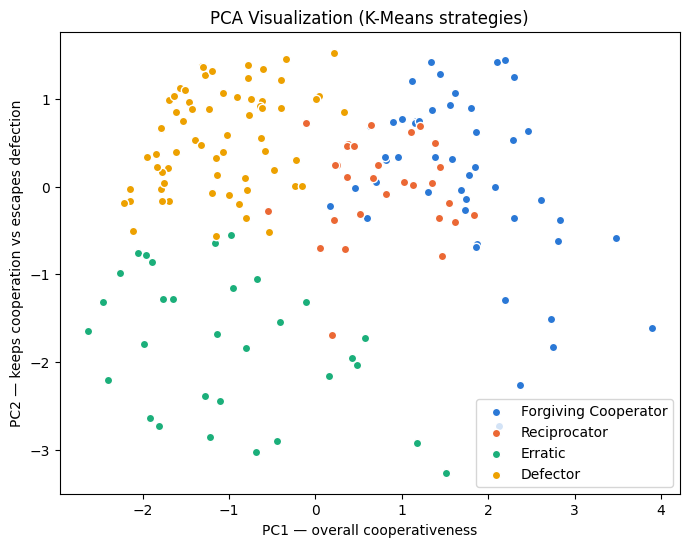

In [31]:
plt.figure(figsize=(8, 6))
for s in strategy_order:
    mask = player_df["strategy"] == s
    plt.scatter(X_pca[mask, 0], X_pca[mask, 1], color=strategy_colors[s], label=s, edgecolor="white")
plt.title("PCA Visualization (K-Means strategies)")
plt.xlabel("PC1 — overall cooperativeness")
plt.ylabel("PC2 — keeps cooperation vs escapes defection")
plt.legend()
plt.savefig(FIG_PATH + "u03_pca.png", dpi=150, bbox_inches="tight")
plt.show()

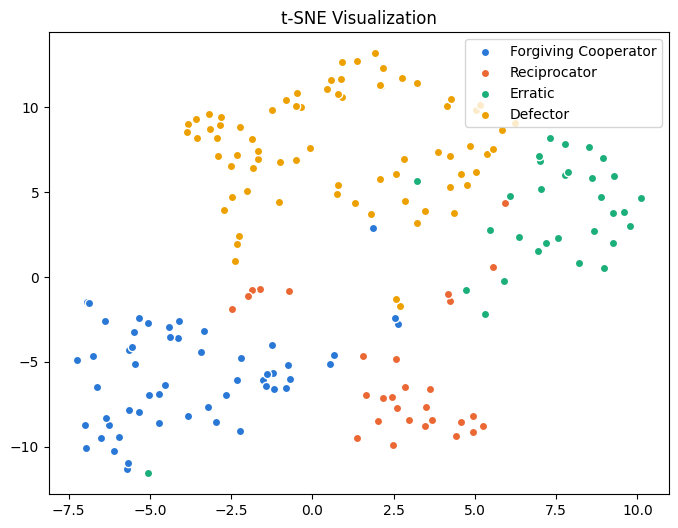

In [32]:
tsne = TSNE(n_components=2, random_state=42)
X_tsne = tsne.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))
for s in strategy_order:
    mask = player_df["strategy"] == s
    plt.scatter(X_tsne[mask, 0], X_tsne[mask, 1], color=strategy_colors[s], label=s, edgecolor="white")
plt.title("t-SNE Visualization")
plt.legend()
plt.show()

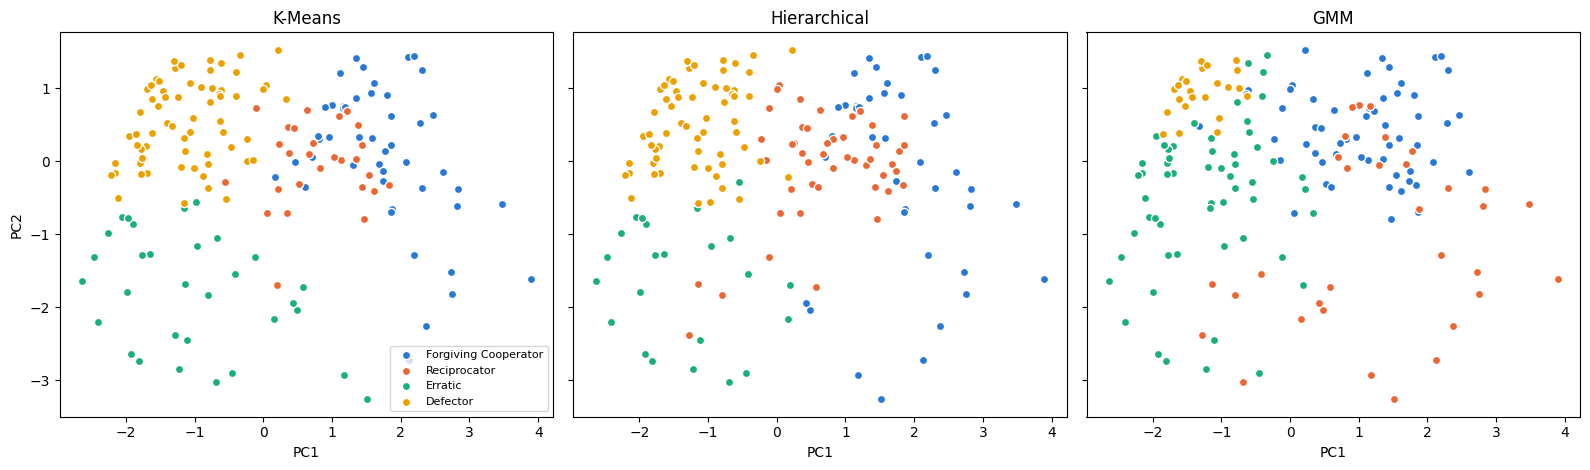

In [33]:
# The three models on the same PCA plot
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharex=True, sharey=True)
for ax, (model, (col, labels)) in zip(axes, models.items()):
    for s in strategy_order:
        mask = player_df[col] == s
        ax.scatter(X_pca[mask, 0], X_pca[mask, 1], color=strategy_colors[s], label=s, edgecolor="white", s=35)
    ax.set_title(model)
    ax.set_xlabel("PC1")
axes[0].set_ylabel("PC2")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG_PATH + "u04_model_comparison_pca.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretation**
- **PC1 (42%)** is **overall cooperativeness**: all features have positive weights.
- **PC2 (24%)** separates players who **keep** mutual cooperation (`p_c_after_CC` +0.67) from players who **escape** mutual defection (`p_c_after_DD` −0.64).
- Together they show 67% of the information. The **Defectors** form a compact group on the left. The other strategies sit next to each other along a continuum, which is why the silhouette scores are moderate. t-SNE shows the same four groups.
- In the comparison plot, K-Means and Hierarchical look similar, while GMM mixes the groups.

## 9. Cluster Interpretation: what does each strategy do?

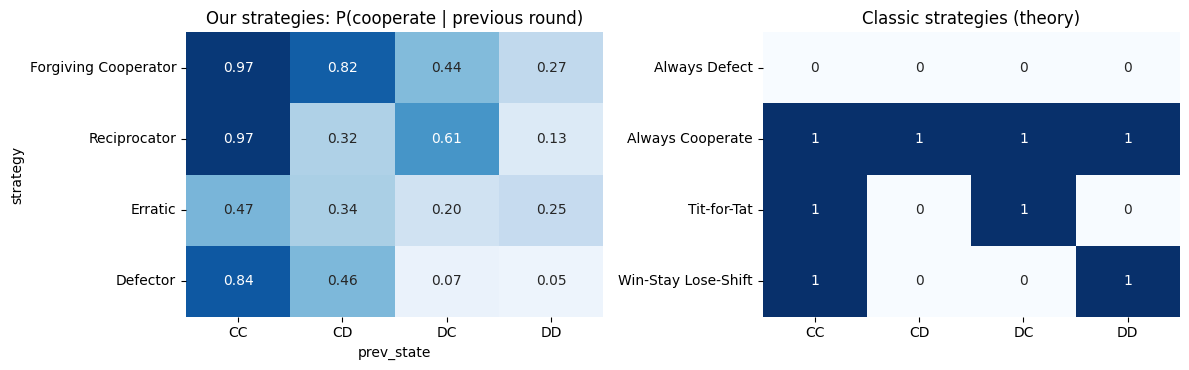

In [34]:
df = df.merge(player_df[["strategy"]], left_on="player", right_index=True)

# Real behaviour of each group (no smoothing): chance of cooperating after each previous state
observed = df[df["prev_state"] != "NDND"].pivot_table(index="strategy", columns="prev_state", values="y", aggfunc="mean")
observed = observed.loc[strategy_order]

classic = pd.DataFrame({"CC": [0, 1, 1, 1], "CD": [0, 1, 0, 0], "DC": [0, 1, 1, 0], "DD": [0, 1, 0, 1]},
                       index=["Always Defect", "Always Cooperate", "Tit-for-Tat", "Win-Stay Lose-Shift"])

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
sns.heatmap(observed, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=axes[0], cbar=False)
axes[0].set_title("Our strategies: P(cooperate | previous round)")
sns.heatmap(classic, annot=True, fmt=".0f", cmap="Blues", vmin=0, vmax=1, ax=axes[1], cbar=False)
axes[1].set_title("Classic strategies (theory)")
plt.tight_layout()
plt.savefig(FIG_PATH + "u05_strategies_vs_classic.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretation (real behavior, without smoothing)**
- **Reciprocator ≈ Tit-for-Tat:** cooperates after the opponent cooperated (CC 0.97, DC 0.61) and defects after the opponent defected (CD 0.32, DD 0.13).
- **Forgiving Cooperator ≈ Always Cooperate:** even after being betrayed (CD), they cooperate 82% of the time.
- **Defector ≈ Always Defect:** after DC and DD they cooperate only 5–7% of the time. In the rare case of mutual cooperation they mostly continue (0.84), but this happens only ~2 times per player.
- **Erratic:** no clear rule; every value is between 0.2 and 0.5, closest to random play.

## 10. Decision Analysis

### 10.1 Which strategies are most common? Fixed vs Random partner

In [35]:
strategy_by_treatment = pd.crosstab(player_df["strategy"], player_df["treatment"]).loc[strategy_order]
print(strategy_by_treatment)
print()
print((pd.crosstab(player_df["strategy"], player_df["treatment"], normalize="columns") * 100).round(1).loc[strategy_order])

chi2, p, dof, expected = chi2_contingency(strategy_by_treatment)
print(f"\nChi-square test: p = {p:.6f}")

treatment             fix  rand
strategy                       
Forgiving Cooperator   37    18
Reciprocator           22     7
Erratic                10    21
Defector               23    50

treatment              fix  rand
strategy                        
Forgiving Cooperator  40.2  18.8
Reciprocator          23.9   7.3
Erratic               10.9  21.9
Defector              25.0  52.1

Chi-square test: p = 0.000003


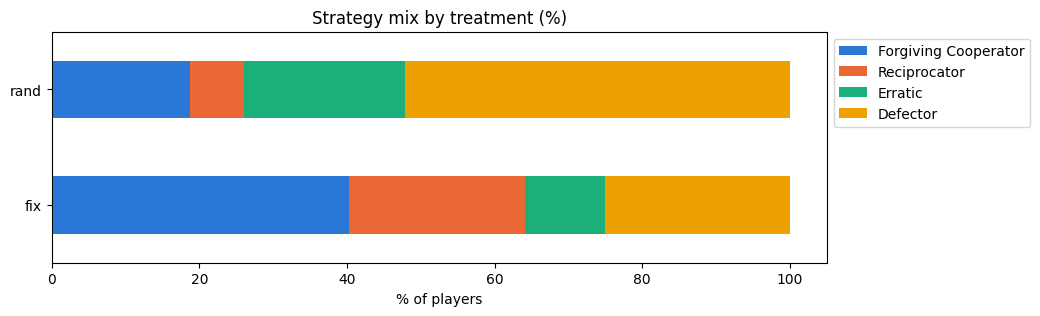

In [36]:
share = pd.crosstab(player_df["treatment"], player_df["strategy"], normalize="index")[strategy_order] * 100
share.plot(kind="barh", stacked=True, figsize=(10, 3), color=[strategy_colors[s] for s in strategy_order])
plt.title("Strategy mix by treatment (%)")
plt.xlabel("% of players")
plt.ylabel("")
plt.legend(bbox_to_anchor=(1, 1))
plt.savefig(FIG_PATH + "u06_strategy_by_treatment.png", dpi=150, bbox_inches="tight")
plt.show()

### 10.2 Cooperation across rounds for each strategy

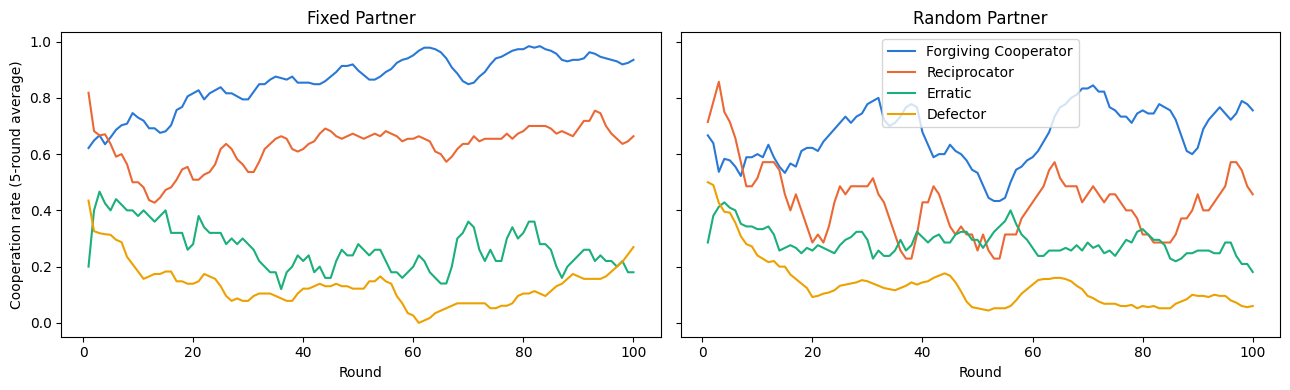

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, (treatment, title) in zip(axes, [("fix", "Fixed Partner"), ("rand", "Random Partner")]):
    data = df[df["treatment"] == treatment]
    coop_by_round = data.groupby(["round", "strategy"])["y"].mean().unstack()
    for s in strategy_order:
        if s in coop_by_round:
            ax.plot(coop_by_round[s].rolling(5, min_periods=1).mean(), color=strategy_colors[s], label=s)
    ax.set_title(title)
    ax.set_xlabel("Round")
axes[0].set_ylabel("Cooperation rate (5-round average)")
axes[1].legend()
plt.tight_layout()
plt.savefig(FIG_PATH + "u07_coop_over_rounds.png", dpi=150, bbox_inches="tight")
plt.show()

### 10.3 What makes players change their decision?

In [38]:
changes = df[df["round"] > 1].copy()
changes["phase"] = pd.cut(changes["round"], [1, 10, 50, 90, 100], labels=["2-10", "11-50", "51-90", "91-100"])

summary = []
for factor in ["prev_state", "prev_payoff", "prev_opp", "strategy", "treatment", "phase"]:
    rates = changes.groupby(factor, observed=True)["switched"].mean() * 100
    print(f"\n% changed decision, by {factor}:")
    print(rates.round(1).to_string())
    summary.append({"factor": factor, "lowest %": rates.min(), "highest %": rates.max(),
                    "difference": rates.max() - rates.min()})


% changed decision, by prev_state:
prev_state
CC     7.5
CD    41.6
DC    21.1
DD    11.9

% changed decision, by prev_payoff:
prev_payoff
0.0    41.6
1.0    11.9
3.0     7.5
4.0    21.1

% changed decision, by prev_opp:
prev_opp
C    12.5
D    19.9

% changed decision, by strategy:
strategy
Defector                10.1
Erratic                 33.9
Forgiving Cooperator    12.5
Reciprocator            23.3

% changed decision, by treatment:
treatment
fix     13.9
rand    19.5

% changed decision, by phase:
phase
2-10      30.7
11-50     18.9
51-90     13.2
91-100    10.3


In [39]:
# Factors ranked by how much the change rate differs between their values
pd.DataFrame(summary).set_index("factor").sort_values("difference", ascending=False).round(1)

,lowest %,highest %,difference
factor,,,
prev_state,7.5,41.6,34.0
prev_payoff,7.5,41.6,34.0
strategy,10.1,33.9,23.8
phase,10.3,30.7,20.5
prev_opp,12.5,19.9,7.3
treatment,13.9,19.5,5.6


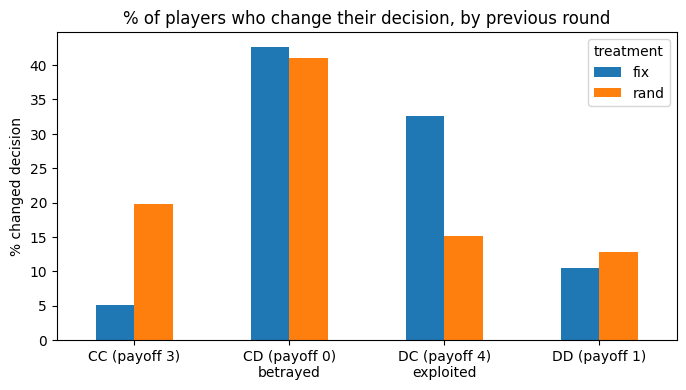

In [40]:
switch_by_state = changes.groupby(["prev_state", "treatment"])["switched"].mean().unstack() * 100

switch_by_state.plot(kind="bar", figsize=(8, 4), rot=0)
plt.title("% of players who change their decision, by previous round")
plt.xticks(range(4), ["CC (payoff 3)", "CD (payoff 0)\nbetrayed", "DC (payoff 4)\nexploited", "DD (payoff 1)"])
plt.xlabel("")
plt.ylabel("% changed decision")
plt.savefig(FIG_PATH + "u08_change_by_previous_round.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretation**
- **The previous round's outcome (and its payoff) is the strongest factor.** After being betrayed (CD, payoff 0), 41.6% of players change their decision. After mutual cooperation (CC, payoff 3), only 7.5% do.
- **The strategy group is second:** Erratic players change their decision in 34% of rounds, Defectors in only 10%.
- **Game phase:** players change more at the start (31% in rounds 2–10) and settle down later (10% in the last 10 rounds).
- **The opponent's previous move alone** and the **treatment** make a smaller difference (7 and 6 percentage points). What matters is the *combination* of both players' moves.
- After exploiting a cooperator (DC), more players switch back to cooperation with a **fixed partner**, who could retaliate, than with a random partner (see chart).

### 10.4 Which strategy earns the most?

In [41]:
payoff_table = player_df.pivot_table(index="strategy", columns="treatment", values="mean_payoff", aggfunc="mean")
payoff_table.loc[strategy_order].round(2)

treatment,fix,rand
strategy,,
Forgiving Cooperator,2.47,1.19
Reciprocator,2.26,1.46
Erratic,2.13,1.59
Defector,1.42,1.71


**Interpretation:** the best strategy depends on the setting.
- **Fixed partner:** cooperation pays. Forgiving Cooperators earn the most (2.47 per round) and Defectors the least (1.42).
- **Random partner:** the ranking reverses. Defectors earn the most (1.71) and Forgiving Cooperators the least (1.19), because a new opponent cannot punish them later.

This explains why defection is much more common with changing partners.

### 10.5 Do the survey answers agree with the strategies?

In [42]:
survey_check = player_df.groupby("strategy")["influenced_by_opponent"].mean() * 100
print("% who said the opponent's previous move influenced them:")
print(survey_check.loc[strategy_order].round(1))

chi2, p, dof, expected = chi2_contingency(pd.crosstab(player_df["strategy"], player_df["influenced_by_opponent"]))
print(f"\nChi-square test: p = {p:.4f}")

% who said the opponent's previous move influenced them:
strategy
Forgiving Cooperator    67.3
Reciprocator            96.6
Erratic                 58.1
Defector                56.2
Name: influenced_by_opponent, dtype: float64

Chi-square test: p = 0.0011


**Interpretation:** the survey was **not** used to build the clusters, so it is an independent check. 96.6% of **Reciprocators** (who copy the opponent) said the opponent's previous move influenced them, against 56–67% in the other groups (p = 0.001). The clusters match what players reported about themselves.

## 11. Robustness Check: does the smoothing value change the results?

In [43]:
for alpha in [0.5, 1, 2, 3, 5]:
    test_df = build_player_features(df, alpha=alpha)
    test_X = StandardScaler().fit_transform(test_df[features])
    test_labels = KMeans(n_clusters=4, n_init=10, random_state=42).fit_predict(test_X)
    test_strategy = name_clusters(test_df, test_labels)
    print(f"alpha = {alpha:<4} same groups as alpha=2 (ARI): {adjusted_rand_score(player_df['strategy'], test_strategy):.2f}   "
          f"sizes: {test_strategy.value_counts().reindex(strategy_order).to_dict()}")

alpha = 0.5  same groups as alpha=2 (ARI): 0.52   sizes: {'Forgiving Cooperator': 22, 'Reciprocator': 65, 'Erratic': 39, 'Defector': 62}
alpha = 1    same groups as alpha=2 (ARI): 0.52   sizes: {'Forgiving Cooperator': 22, 'Reciprocator': 63, 'Erratic': 43, 'Defector': 60}
alpha = 2    same groups as alpha=2 (ARI): 1.00   sizes: {'Forgiving Cooperator': 55, 'Reciprocator': 29, 'Erratic': 31, 'Defector': 73}
alpha = 3    same groups as alpha=2 (ARI): 0.88   sizes: {'Forgiving Cooperator': 53, 'Reciprocator': 28, 'Erratic': 27, 'Defector': 80}


alpha = 5    same groups as alpha=2 (ARI): 0.82   sizes: {'Forgiving Cooperator': 57, 'Reciprocator': 25, 'Erratic': 28, 'Defector': 78}


**Interpretation:** for alpha between 2 and 5 we get similar groups (ARI 0.82–1.00) with similar sizes. With very weak smoothing (alpha ≤ 1), players with only 1–2 visits to a state get extreme values of 0 or 1. Forgiving Cooperators and Reciprocators then merge into one large group (~65 players), and a small noisy group (~22 players) appears. **Some smoothing is therefore necessary**, and alpha = 2 is inside the stable range.

## 12. Insights

1. **Four Behavioral Strategies**

   The most common strategy is **Defector** (39%, 73 players), followed by **Forgiving Cooperator** (29%, 55), **Erratic** (16%, 31) and **Reciprocator / Tit-for-Tat** (15%, 29).

2. **Partner Stability and Strategies**

   With a **fixed partner**, most players are Forgiving Cooperators (40%) or Reciprocators (24%). With a **random partner**, more than half are Defectors (52%) and 22% are Erratic. The difference is statistically significant (chi-square p < 0.001).

3. **What Makes Players Change Their Decision**

   The strongest factor is the previous round's outcome: after being betrayed (payoff 0), 41.6% of players change their decision, compared to 7.5% after mutual cooperation. The player's strategy is the second most important factor.

4. **The Best Strategy Depends on the Setting**

   Cooperation earns the most with a fixed partner, while defection earns the most with changing partners.

5. **The Clusters Are Meaningful**

   The survey independently confirms the Reciprocator group (96.6% said the opponent influenced them). K-Means was more stable and better separated than Hierarchical clustering and GMM.

**Overall Conclusion**

Unsupervised learning found four clear player strategies that match classic game-theory strategies (Always Defect, Always Cooperate, Tit-for-Tat) plus an erratic group. Partner stability strongly changes which strategies people use: stable partners encourage cooperation and reciprocity, and changing partners encourage defection.

**Limitations**
- Only 188 players. Apart from the Defectors, strategies change gradually rather than forming separated groups (silhouette 0.32), so players near the border between two groups could belong to either.
- The results need smoothing for rare situations (stable for alpha ≥ 2).
- The features only look one round back.

## 13. Save Results and Connection to TrustLab

In [44]:
player_df.drop(columns=["strategy_hc", "strategy_gmm"]).to_csv("../models/player_strategies.csv")
print("Saved ../models/player_strategies.csv")

Saved ../models/player_strategies.csv


The same steps (features → scaling → K-Means with k = 4 → naming) are packaged in the folder `trustlab_unsupervised/`, so the TrustLab app can label a **new** player from their moves. The check below confirms that the packaged model gives the **same strategy for every player** as this notebook.

In [45]:
import sys
sys.path.append("..")
from trustlab_unsupervised.model import StrategyModel

app_model = StrategyModel.load("../models/strategy_model.joblib")
app_labels = pd.Series(app_model.predict_features(player_df), index=player_df.index).map(app_model.cluster_names)
print("Same strategy as this notebook:", (app_labels == player_df["strategy"]).mean() * 100, "% of players")

# Example: label a new player from their moves (each item = my move + opponent's move)
app_model.predict_strategy("CC,CC,CD,DD,DC,CC,CC,CD,DD,DC,CC")["strategy"]

Same strategy as this notebook: 100.0 % of players


'Reciprocator'

**Connection with the supervised model.** In `supervised_integration.ipynb`, the strategy of each player (computed only from earlier rounds) is added to the supervised Logistic Regression. This improves the next-move prediction from ROC-AUC 0.845 to 0.898 (cross-validation over the 12 sessions), and it is the first model that beats the simple rule "the player repeats their previous move".